# 04 · Evaluation protocol and baselines

**Question:** how do we measure a model fairly on this dataset, and how noisy is that measurement?

This notebook fixes the protocol *before* any real model is trained (decision D1 in the project plan):

1. **Splits:** 5 folds grouped by baby and stratified by label, repeated with 5 seeds, giving 25
   train/test splits. They are saved to `metadata/folds.csv`, and every model in 05 and 07 uses exactly these.
2. **Metrics:** balanced accuracy and macro-F1 over all 8 classes are primary. Accuracy is always shown next
   to the always-hungry 0.797.
3. **Baselines** that every model must beat.
4. **A leakage demonstration:** the same model scored with and without grouping by baby.
5. **The noise floor:** how much scores move between repeats and between resampled babies.

Code: `src/splits.py` and `src/metrics.py`, tested in `tests/test_splits.py` and `tests/test_metrics.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from src import viz
from src.audio import CLASSES, load_clean_index
from src.features import feature_table
from src.metrics import (balanced_accuracy, cluster_bootstrap, encode, interval, macro_f1,
                         paired_bootstrap, per_class_table, predictions_by_repeat, repeat_scores,
                         scores, summarize)
from src.splits import FOLDS_CSV, load_folds, make_folds, oof_predict, outer_splits, repeats, save_predictions

viz.set_style()
pd.set_option("display.width", 140)
idx = load_clean_index()
y = idx["label"].to_numpy()
t = encode(y)
print(f"{len(idx)} clips, {idx['source'].nunique()} babies")

479 clips, 226 babies


## 1. The 25 outer splits

`StratifiedGroupKFold` puts all clips of a baby into the same fold, and balances the label mix
across folds as well as the grouping allows. Repeating this with 5 seeds gives 5 different
partitions. In each one, every clip is predicted exactly once by a model that never saw its baby.
The file is written once and then only read.

In [2]:
folds = make_folds(idx)
FOLDS_CSV.parent.mkdir(exist_ok=True)
folds.to_csv(FOLDS_CSV, index=False)
folds = load_folds(idx)
print(f"saved {FOLDS_CSV.relative_to(REPO)}: {len(folds)} clips x {len(repeats(folds))} repeats")

# Checks: no baby on both sides of any split; every clip tested once per repeat
for r in repeats(folds):
    tested = []
    for k, train, test in outer_splits(folds, r):
        assert not set(idx["source"].iloc[train]) & set(idx["source"].iloc[test]), (r, k)
        tested += list(test)
    assert sorted(tested) == list(range(len(idx)))
print("checked: no baby appears on both sides of any of the 25 splits; every clip tested once per repeat")

saved metadata/folds.csv: 479 clips x 5 repeats
checked: no baby appears on both sides of any of the 25 splits; every clip tested once per repeat


In [3]:
# Repeat r0: clips and babies of each class in each test fold
clips = pd.crosstab(idx["label"], folds["r0"]).reindex(CLASSES)
babies = idx.assign(fold=folds["r0"]).groupby(["label", "fold"])["source"].nunique().unstack(fill_value=0).reindex(CLASSES)
table = clips.astype(str) + " (" + babies.astype(str) + ")"
table.columns = [f"fold {k}" for k in table.columns]
print("clips (babies) per test fold, repeat r0")
table

clips (babies) per test fold, repeat r0


,fold 0,fold 1,fold 2,fold 3,fold 4
label,,,,,
belly_pain,3 (1),2 (2),1 (1),8 (1),2 (2)
burping,2 (2),2 (2),2 (2),2 (1),1 (1)
cold_hot,1 (1),0 (0),1 (1),0 (0),5 (1)
discomfort,4 (3),5 (4),4 (3),4 (3),4 (1)
hungry,76 (40),77 (41),77 (42),76 (41),76 (41)
lonely,3 (3),2 (1),2 (1),2 (1),2 (2)
scared,2 (1),1 (1),1 (1),0 (0),1 (1)
tired,6 (4),6 (4),6 (3),5 (3),5 (3)


In [4]:
# Over all 25 splits: how many test folds contain no baby of a class?
empty = {c: sum(int((idx.loc[folds[r] == k, "label"] == c).sum() == 0)
                for r in repeats(folds) for k in range(5)) for c in CLASSES}
print("test folds (of 25) with no clip of the class:", {c: n for c, n in empty.items() if n})
print("This is why metrics are computed on the pooled predictions of a whole repeat, not per fold.")

test folds (of 25) with no clip of the class: {'cold_hot': 10, 'scared': 5}
This is why metrics are computed on the pooled predictions of a whole repeat, not per fold.


## 2. Metrics, and why accuracy misleads here

| metric | role | definition |
|---|---|---|
| **balanced accuracy** | primary | mean recall over the classes, so each class counts equally |
| **macro-F1** | primary | mean F1 over all 8 classes; a class that is never predicted counts as 0 |
| accuracy, MCC | secondary | accuracy is always shown next to the always-hungry 0.797 |
| log-loss, Brier, top-3 accuracy | probability quality | how good the predicted probabilities are; top-3 is what a demo would show |

**How they are computed:** within one repeat, the predictions of the 5 test folds are pooled
(one prediction per clip), and each metric is computed once over all 479 clips. Results are the
mean ± std over the 5 repeats. Per-fold metrics would be meaningless here, because some test folds have no
*cold_hot* or *scared* clip at all.

A small example shows the difference between the metrics. There are 8 clips: 4 *hungry*, 2 *tired*,
2 *scared*. The model gets every hungry clip right, never says *tired*, and gets 1 of the 2 *scared*.

In [5]:
ex_true = encode(["hungry"] * 4 + ["tired"] * 2 + ["scared"] * 2)
ex_pred = encode(["hungry"] * 6 + ["scared", "hungry"])
s = scores(ex_true, ex_pred)
print(f"accuracy {s['accuracy']:.3f}   balanced accuracy {s['balanced_accuracy']:.3f}   macro-F1 {s['macro_f1']:.3f}")
per_class_table(ex_true, ex_pred, groups=np.arange(8)).loc[["hungry", "tired", "scared"], ["clips", "predicted", "precision", "recall", "f1"]]

accuracy 0.625   balanced accuracy 0.500   macro-F1 0.465


,clips,predicted,precision,recall,f1
hungry,4,7,0.571429,1.0,0.727273
tired,2,0,NaN,0.0,0.000000
scared,2,1,1.000000,0.5,0.666667


In [6]:
# The same on the real data: always answer "hungry"
always_hungry = np.full(len(t), CLASSES.index("hungry"))
pd.Series(scores(t, always_hungry)).round(3).to_frame("always hungry, all 479 clips")

,"always hungry, all 479 clips"
balanced_accuracy,0.125
macro_f1,0.111
accuracy,0.797
mcc,0.000


Accuracy is 0.797 for a model that has learnt nothing. Balanced accuracy and macro-F1 show that
it fails on 7 of the 8 classes.

## 3. Baselines on the saved folds

- **Majority:** always predicts the most common class in the training folds (*hungry*). Its probabilities
  are the training class frequencies.
- **Prior-random:** guesses at random in proportion to the training class frequencies, with the same
  probabilities.

Both are fitted per split like any other model. Their predictions are saved to `results/predictions/`
so later notebooks can compare against them clip by clip.

In [7]:
class PriorBaseline:
    """Uses only the training class frequencies. Probabilities are always those frequencies;
    the predicted class is the most frequent one ('majority') or a random draw from them ('random')."""
    def __init__(self, mode, seed=0):
        self.mode, self.rng = mode, np.random.default_rng(seed)

    def fit(self, X, y):
        self.classes_, counts = np.unique(y, return_counts=True)
        self.prior_ = counts / counts.sum()
        return self

    def predict_proba(self, X):
        return np.tile(self.prior_, (len(X), 1))

    def predict(self, X):
        if self.mode == "majority":
            return np.repeat(self.classes_[self.prior_.argmax()], len(X))
        return self.rng.choice(self.classes_, size=len(X), p=self.prior_)


dummy_X = np.zeros((len(idx), 1))
baseline = {"majority": oof_predict(lambda: PriorBaseline("majority"), dummy_X, y, folds)}
seeds = iter(range(1000))
baseline["prior_random"] = oof_predict(lambda: PriorBaseline("random", next(seeds)), dummy_X, y, folds)
for name, pred in baseline.items():
    save_predictions(name, pred, idx)
pd.concat({name: summarize(pred)["mean"] for name, pred in baseline.items()}, axis=1).round(3).T

,balanced_accuracy,macro_f1,accuracy,mcc,log_loss,brier,top3_accuracy
majority,0.125,0.111,0.797,0.000,0.887,0.357,0.9
prior_random,0.132,0.132,0.654,0.019,0.887,0.357,0.9


Both baselines have the same probabilities, so their log-loss, Brier and top-3 are identical.
These are the reference values for probability quality.

## 4. Leakage demonstration: grouped vs clip-level folds

One simple model with fixed settings, nothing tuned: median imputation → standardisation →
logistic regression (C = 0.1, balanced class weights) on the 225 band-limited features from
notebook 03. It is scored twice:

- with the **grouped** folds above;
- with ordinary **clip-level** stratified folds, where clips of the same baby can sit on both sides.

Notebook 02 showed that a baby's clips resemble each other (ICC up to 0.43). With clip-level
folds the model can score by recognising babies it has heard in training. **This section is the
only place clip-level folds are used. Its numbers are a demonstration, never a result.**

In [8]:
X = feature_table()


def simple_model():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000))


clip_folds = make_folds(idx, grouped=False)
leaky = sum(bool(set(idx["source"].iloc[tr]) & set(idx["source"].iloc[te]))
            for r in repeats(clip_folds) for _, tr, te in outer_splits(clip_folds, r))
print(f"clip-level folds: {leaky} of 25 splits have babies on both sides")

demo = {"grouped by baby": oof_predict(simple_model, X, y, folds),
        "clip-level (leaky)": oof_predict(simple_model, X, y, clip_folds)}
summary = pd.concat({name: summarize(pred) for name, pred in demo.items()}, axis=0)
summary.loc[(slice(None), ["balanced_accuracy", "macro_f1", "accuracy", "top3_accuracy"]), :].round(3)

clip-level folds: 25 of 25 splits have babies on both sides


mean    std
grouped by baby    balanced_accuracy  0.125  0.006
                   macro_f1           0.118  0.004
                   accuracy           0.504  0.011
                   top3_accuracy      0.825  0.005
clip-level (leaky) balanced_accuracy  0.271  0.010
                   macro_f1           0.215  0.011
                   accuracy           0.513  0.024
                   top3_accuracy      0.858  0.009

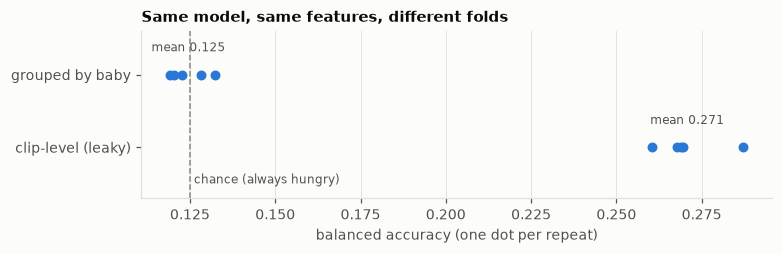

In [9]:
fig, ax = plt.subplots(figsize=(7, 2.2), constrained_layout=True)
for i, (name, pred) in enumerate(demo.items()):
    v = repeat_scores(pred)["balanced_accuracy"]
    ax.scatter(v, np.full(len(v), i), color=viz.BLUE, s=30, zorder=3)
    ax.text(v.mean(), i - 0.32, f"mean {v.mean():.3f}", ha="center", fontsize=8, color=viz.INK_2)
ax.axvline(0.125, color=viz.GREY, ls="--", lw=1)
ax.text(0.125, 1.45, " chance (always hungry)", color=viz.INK_2, fontsize=8, va="center")
ax.set_yticks([0, 1], list(demo))
ax.set_ylim(1.7, -0.6)
ax.grid(axis="y", visible=False)
ax.set(xlabel="balanced accuracy (one dot per repeat)", title="Same model, same features, different folds")
plt.show()

## 5. The noise floor

Two sources of uncertainty:

- **Split variation:** how much a score moves between the 5 repeats (the std above).
- **Sampling variation:** with these particular 226 babies, how different could the score have been?
  A **cluster bootstrap** draws 226 babies with replacement, takes all their clips, and recomputes
  the score (averaged over the 5 repeats). This is done 1000 times, and the middle 95% is the interval.

For comparing two models, the **paired** bootstrap computes both on the same resampled babies and
looks at the difference. This removes the variation the two models share.

In [10]:
groups = idx["source"].to_numpy()
models = {"majority": baseline["majority"], "prior_random": baseline["prior_random"],
          "logistic regression (grouped)": demo["grouped by baby"]}
rows, boots = [], {}
for name, pred in models.items():
    preds = predictions_by_repeat(pred, len(idx))
    for metric_name, metric in [("balanced_accuracy", balanced_accuracy), ("macro_f1", macro_f1)]:
        b = cluster_bootstrap(t, preds, groups, metric=metric, n_boot=1000, seed=0)
        boots[(name, metric_name)] = b
        per_rep = repeat_scores(pred)[metric_name]
        lo, hi = interval(b)
        rows.append({"model": name, "metric": metric_name, "mean over repeats": per_rep.mean(),
                     "std over repeats": per_rep.std(ddof=1), "95% low": lo, "95% high": hi})
noise = pd.DataFrame(rows).set_index(["model", "metric"])
missing = (boots[("majority", "balanced_accuracy")] > 0.1251).mean()
print(f"{missing:.1%} of bootstrap draws contain no baby of at least one class; in those draws balanced accuracy "
      "averages over 7 classes, so always-hungry scores 1/7 = 0.143 instead of 0.125")
noise.round(3)

6.7% of bootstrap draws contain no baby of at least one class; in those draws balanced accuracy averages over 7 classes, so always-hungry scores 1/7 = 0.143 instead of 0.125


mean over repeats  std over repeats  95% low  95% high
model                         metric                                                                   
majority                      balanced_accuracy              0.125             0.000    0.125     0.143
                              macro_f1                       0.111             0.000    0.106     0.130
prior_random                  balanced_accuracy              0.132             0.007    0.119     0.151
                              macro_f1                       0.132             0.007    0.118     0.150
logistic regression (grouped) balanced_accuracy              0.125             0.006    0.098     0.177
                              macro_f1                       0.118             0.004    0.099     0.147

In [11]:
# Paired comparison: logistic regression (grouped) minus each baseline, balanced accuracy
lr = predictions_by_repeat(demo["grouped by baby"], len(idx))
rows = []
for name in ["majority", "prior_random"]:
    d = paired_bootstrap(t, lr, predictions_by_repeat(baseline[name], len(idx)), groups, n_boot=1000, seed=0)
    lo, hi = interval(d)
    rows.append({"comparison": f"logistic regression - {name}", "mean difference": d.mean(),
                 "95% low": lo, "95% high": hi, "share of draws > 0": (d > 0).mean()})
pd.DataFrame(rows).set_index("comparison").round(3)

,mean difference,95% low,95% high,share of draws > 0
comparison,,,,
logistic regression - majority,0.003,-0.027,0.043,0.527
logistic regression - prior_random,-0.004,-0.038,0.042,0.393


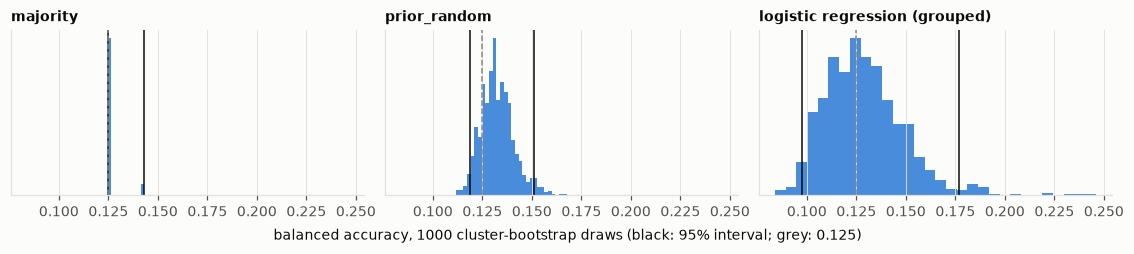

In [12]:
fig, axes = viz.small_multiples(3, ncols=3, panel=(3.4, 2.2), sharex=True)
for ax, name in zip(axes, models):
    b = boots[(name, "balanced_accuracy")]
    ax.hist(b, bins=30, color=viz.BLUE, alpha=0.85)
    lo, hi = interval(b)
    for v in (lo, hi):
        ax.axvline(v, color=viz.INK, lw=1)
    ax.axvline(0.125, color=viz.GREY, ls="--", lw=1)
    ax.set_title(name, fontsize=9)
    ax.set_yticks([])
fig.supxlabel("balanced accuracy, 1000 cluster-bootstrap draws (black: 95% interval; grey: 0.125)", fontsize=9)
plt.show()

## 6. Findings

All numbers below are printed by the cells above.

1. **The 25 splits are saved and checked.** `metadata/folds.csv` holds 5 repeats × 5 grouped folds.
   No baby is on both sides of any split, and every clip is predicted once per repeat. *cold_hot* is
   absent from 10 of the 25 test folds and *scared* from 5, which is why every metric is computed on
   the pooled predictions of a whole repeat.
2. **Accuracy rewards doing nothing.** Always answering *hungry* gets accuracy 0.797 but balanced
   accuracy 0.125, macro-F1 0.111 and MCC 0. On the saved folds, the majority baseline scores
   balanced accuracy 0.125 and macro-F1 0.111. Prior-random scores 0.132 ± 0.007 on both. For
   probabilities, the reference is log-loss 0.887 and Brier 0.357. **Top-3 accuracy is already 0.900** just
   from listing the three most common classes, so a "top-3" display only means something above that.
3. **Grouping by baby changes the answer.** The same untuned logistic regression on the same
   features scores balanced accuracy **0.271 ± 0.010 with clip-level folds** (macro-F1 0.215), where all 25
   splits have babies on both sides. With **grouped folds** it scores **0.125 ± 0.006** (macro-F1 0.118).
   More than half of the clip-level score is the model recognising babies it has heard. Grouped, this
   model is no better than the baselines: the paired difference from majority is +0.003 (95% interval
   −0.027 to +0.043). It is untuned, and notebook 05 tunes a fixed menu of models inside the training folds. But the bar is now
   clear.
4. **The noise floor.** Scores move by only about 0.006–0.007 balanced accuracy between repeats. But the
   cluster bootstrap over babies gives the grouped logistic regression an interval of 0.098–0.177. The
   paired intervals against the baselines are about 0.07 wide. A model–model difference smaller than
   roughly 0.035–0.04 balanced accuracy cannot be told apart from noise with these 226 babies, so the
   paired bootstrap, not the repeat std, decides comparisons in 05.
5. **A detail of the bootstrap.** Some resamples contain no baby of a rare class, and those draws average
   balanced accuracy over 7 classes. This is why the majority baseline's interval reaches 0.143 (1/7). The
   point estimates always use all 8 classes.